# 02 — Prévision de l'ET0 de J+1 avec LightGBM

**Objectif** : prévoir l'évapotranspiration de référence du **lendemain** (ET0 J+1, mm/j) à partir des 7 derniers jours de météo, pour les deux sites (un seul modèle, le site est une variable catégorielle). Le backend (`aquamind_core/forecast.py`) charge le modèle exporté et ne l'entraîne jamais.

| | |
|---|---|
| **Entrées** | `data/processed/weather_daily_tunisia.parquet`, `weather_daily_japan.parquet` |
| **Sorties** | `models/artifacts/et0_lgbm.txt` (format natif LightGBM), `et0_features.json` (ordre exact des variables), `et0_metrics.json` ; expérience MLflow `02_train_et0_lightgbm` |
| **Durée** | ~1–3 min |

**Protocole** : découpage **temporel** sur la date cible (train ≤ 2022, validation 2023, test 2024–2025), jamais aléatoire. Les deux références sont la persistance (ET0 J+1 = ET0 J) et Hargreaves. Recherche aléatoire de ≤ 20 jeux d'hyperparamètres avec early stopping sur la validation, puis réentraînement sur train + validation.

## 1. Imports, chemins et MLflow

In [19]:
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EXPERIMENT = "02_train_et0_lightgbm"
SEED = 42
np.random.seed(SEED)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "aquamind_core").is_dir())
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("mlflow").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# MLflow : file store local mlruns/ à la racine (équivalent de "file:../mlruns" depuis notebooks/)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)
mlflow.end_run()  # ferme un run resté ouvert par une exécution précédente interrompue
run = mlflow.start_run(run_name=f"{EXPERIMENT}-{time.strftime('%Y%m%d-%H%M%S')}")
T0 = time.perf_counter()
print("Racine :", ROOT)
print("MLflow :", mlflow.get_tracking_uri(), "| run", run.info.run_id)

Racine : c:\Users\ghodh\aquamind
MLflow : file:///c:/Users/ghodh/aquamind/mlruns | run 6eea7d956a2d484dac88d2e2aa2b2b5d


## 2. Chargement

In [20]:
from aquamind_core.config import get_settings

settings = get_settings()
SITE_CODES = {"tunisia": 0, "japan": 1}
SITE_LAT = {"tunisia": settings.farm_lat, "japan": settings.japan_lat}
SITE_LABEL = {"tunisia": "Sidi Bouzid (TN)", "japan": "Niigata (JP)"}
COLORS = {"tunisia": "#d9822b", "japan": "#2b7bb9"}

# variable courte → colonne Open-Meteo
SOURCE = {
    "et0": "et0_fao_evapotranspiration",
    "tmax": "temperature_2m_max",
    "tmin": "temperature_2m_min",
    "rad": "shortwave_radiation_sum",
    "wind": "wind_speed_10m_max",
    "rh": "relative_humidity_2m_mean",
}
daily = pd.concat([pd.read_parquet(PROCESSED / f"weather_daily_{s}.parquet") for s in SITE_CODES])
assert set(SOURCE.values()) <= set(daily.columns), "colonnes manquantes : relancer python -m ingest.run_all"
daily.groupby("site").size()

site
japan      4018
tunisia    4018
dtype: int64

## 3. Variables explicatives

Une ligne correspond au **jour J** (dernier jour connu) ; la cible est l'**ET0 de J+1**.

- `{var}_lag{k}`, k = 1…7 : valeur du jour J−(k−1). Donc `lag1` = jour J, `lag7` = J−6. Variables : ET0, Tmax, Tmin, rayonnement, vent, humidité.
- `{var}_mean3`, `{var}_mean7` : moyennes glissantes sur 3 et 7 jours qui se terminent à J.
- `amp_lag1`, `amp_mean7` : amplitude thermique (Tmax − Tmin).
- `doy_sin`, `doy_cos` : jour de l'année de la **date cible** J+1.
- `site` : 0 = Tunisie, 1 = Japon (catégorielle).

Hors variables : `hargreaves` (référence calculée avec les températures **observées** de J+1, ce qui équivaut à une prévision de température parfaite) et `persistence` (= `et0_lag1`).

In [21]:
def extraterrestrial_radiation(lat_deg: float, doy: np.ndarray) -> np.ndarray:
    """Rayonnement extraterrestre Ra (MJ/m²/j), FAO-56 éq. 21."""
    phi = np.radians(lat_deg)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    return 24 * 60 / np.pi * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta)
                                            + np.cos(phi) * np.cos(delta) * np.sin(ws))


def hargreaves_et0(tmax, tmin, ra):
    """ET0 de Hargreaves-Samani (mm/j), FAO-56 éq. 52."""
    return 0.0023 * 0.408 * ra * ((tmax + tmin) / 2 + 17.8) * np.sqrt(np.clip(tmax - tmin, 0, None))


def build_features(daily: pd.DataFrame) -> pd.DataFrame:
    """Table (jour J, site) → variables, cible ET0(J+1) et références."""
    out = []
    for site, g in daily.groupby("site"):
        g = g.sort_index().asfreq("D")  # un éventuel jour manquant devient NaN (pas de décalage silencieux)
        f = pd.DataFrame(index=g.index)
        for short, col in SOURCE.items():
            for k in range(1, 8):
                f[f"{short}_lag{k}"] = g[col].shift(k - 1)
        for short, col in SOURCE.items():
            f[f"{short}_mean3"] = g[col].rolling(3).mean()
            f[f"{short}_mean7"] = g[col].rolling(7).mean()
        amp = g[SOURCE["tmax"]] - g[SOURCE["tmin"]]
        f["amp_lag1"] = amp
        f["amp_mean7"] = amp.rolling(7).mean()
        target_date = f.index + pd.Timedelta(days=1)
        doy = target_date.dayofyear.to_numpy()
        f["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
        f["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
        f["site"] = SITE_CODES[site]
        # --- hors variables explicatives ---
        f["site_name"] = site
        f["target_date"] = target_date
        f["y"] = g[SOURCE["et0"]].shift(-1)
        f["persistence"] = g[SOURCE["et0"]]
        ra_next = extraterrestrial_radiation(SITE_LAT[site], doy)
        f["hargreaves"] = hargreaves_et0(g[SOURCE["tmax"]].shift(-1).to_numpy(),
                                         g[SOURCE["tmin"]].shift(-1).to_numpy(), ra_next)
        out.append(f)
    return pd.concat(out)


NOT_FEATURES = ["site_name", "target_date", "y", "persistence", "hargreaves"]
table = build_features(daily)
FEATURES = [c for c in table.columns if c not in NOT_FEATURES]
table = table.dropna(subset=FEATURES + ["y"])
print(len(FEATURES), "variables ;", len(table), "lignes utilisables")
table[FEATURES[:8] + ["y", "persistence", "hargreaves"]].head()

59 variables ; 8022 lignes utilisables


,et0_lag1,et0_lag2,et0_lag3,et0_lag4,et0_lag5,et0_lag6,et0_lag7,tmax_lag1,y,persistence,hargreaves
date,,,,,,,,,,,
2015-01-07,1.45,0.71,0.93,0.57,1.16,0.84,0.95,1.7,0.97,1.45,0.343620
2015-01-08,0.97,1.45,0.71,0.93,0.57,1.16,0.84,2.1,0.97,0.97,0.326691
2015-01-09,0.97,0.97,1.45,0.71,0.93,0.57,1.16,2.3,1.08,0.97,0.345353
2015-01-10,1.08,0.97,0.97,1.45,0.71,0.93,0.57,2.6,0.72,1.08,0.413619
2015-01-11,0.72,1.08,0.97,0.97,1.45,0.71,0.93,2.4,0.95,0.72,0.439116


## 4. Découpage temporel (sur la date cible)

In [22]:
split = np.select(
    [table["target_date"] <= "2022-12-31", table["target_date"] <= "2023-12-31"],
    ["train", "val"], default="test")
table["split"] = split
display(table.groupby(["split", "site_name"]).agg(n=("y", "size"), debut=("target_date", "min"),
                                                  fin=("target_date", "max")))
train, val, test = (table[table["split"] == s] for s in ("train", "val", "test"))
X_tr, y_tr = train[FEATURES], train["y"]
X_va, y_va = val[FEATURES], val["y"]
X_te, y_te = test[FEATURES], test["y"]

n      debut        fin
split site_name                            
test  japan       731 2024-01-01 2025-12-31
      tunisia     731 2024-01-01 2025-12-31
train japan      2915 2015-01-08 2022-12-31
      tunisia    2915 2015-01-08 2022-12-31
val   japan       365 2023-01-01 2023-12-31
      tunisia     365 2023-01-01 2023-12-31

## 5. Recherche d'hyperparamètres (≤ 20 essais, early stopping sur 2023)

In [23]:
N_TRIALS = 20
rng = np.random.default_rng(SEED)
SPACE = {
    "num_leaves": [15, 31, 63],
    "learning_rate": [0.02, 0.03, 0.05, 0.1],
    "min_child_samples": [10, 20, 40, 80],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.9],
    "reg_lambda": [0.0, 0.1, 1.0, 5.0],
}
BASE = dict(objective="regression", metric="l1", n_estimators=3000, subsample_freq=1,
            random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)

trials = []
trial_models = {}  # conservés pour mesurer ensuite l'erreur sur le train
t_search = time.perf_counter()
for i in range(N_TRIALS):
    params = {k: (v[rng.integers(len(v))]) for k, v in SPACE.items()}
    params = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, np.floating) else v)
              for k, v in params.items()}
    model = lgb.LGBMRegressor(**BASE, **params)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], categorical_feature=["site"],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    mae = mean_absolute_error(y_va, model.predict(X_va, num_iteration=model.best_iteration_))
    trials.append({**params, "trial": i, "best_iteration": model.best_iteration_, "val_mae": mae})
    trial_models[i] = model
    mlflow.log_metric("trial_val_mae", mae, step=i)
trials = pd.DataFrame(trials).sort_values("val_mae")
print(f"{N_TRIALS} essais en {time.perf_counter() - t_search:.1f} s")
trials.head(10).round(4)

20 essais en 15.3 s


,num_leaves,learning_rate,min_child_samples,subsample,colsample_bytree,reg_lambda,trial,best_iteration,val_mae
15,31,0.10,80,0.85,0.9,0.1,15,119,0.6050
16,15,0.05,40,0.70,0.9,0.0,16,227,0.6074
0,15,0.10,40,0.85,0.7,5.0,0,71,0.6078
9,31,0.02,40,0.70,0.9,1.0,9,365,0.6088
17,63,0.02,80,1.00,0.9,1.0,17,278,0.6089
18,31,0.05,20,1.00,0.7,0.1,18,126,0.6093
12,31,0.02,40,0.85,0.5,0.0,12,376,0.6106
5,31,0.02,10,0.85,0.9,0.0,5,234,0.6111
13,31,0.05,80,0.85,0.5,5.0,13,232,0.6121
14,31,0.05,10,0.70,0.9,5.0,14,252,0.6135


## 6. Modèle final : réentraînement sur train + validation
On garde les hyperparamètres du meilleur essai et on fixe le nombre d'arbres à la `best_iteration` trouvée par early stopping. Le test 2024–2025 n'a été utilisé à aucune étape.

In [24]:
best = trials.iloc[0].to_dict()
INT_PARAMS = {"num_leaves", "min_child_samples"}
BEST_PARAMS = {k: int(best[k]) if k in INT_PARAMS else float(best[k]) for k in SPACE}
N_ESTIMATORS = int(best["best_iteration"])
print("Meilleurs hyperparamètres :", BEST_PARAMS, "| arbres :", N_ESTIMATORS,
      f"| MAE validation {best['val_mae']:.4f}")

final_params = {**BASE, **BEST_PARAMS, "n_estimators": N_ESTIMATORS}
final = lgb.LGBMRegressor(**final_params)
X_trva = pd.concat([X_tr, X_va])
y_trva = pd.concat([y_tr, y_va])
final.fit(X_trva, y_trva, categorical_feature=["site"])
mlflow.log_params({**BEST_PARAMS, "n_estimators": N_ESTIMATORS, "n_trials": N_TRIALS,
                   "n_features": len(FEATURES), "train_rows": len(X_trva),
                   "split": "train<=2022, val=2023, test=2024-2025 (date cible)"})
mlflow.log_metric("val_mae_best_trial", float(best["val_mae"]))

Meilleurs hyperparamètres : {'num_leaves': 31, 'learning_rate': 0.1, 'min_child_samples': 80, 'subsample': 0.85, 'colsample_bytree': 0.9, 'reg_lambda': 0.1} | arbres : 119 | MAE validation 0.6050


## 7. Évaluation sur le test 2024–2025, par site, comparée aux références

In [25]:
test = test.copy()
test["lgbm"] = final.predict(X_te)


def scores(y, p) -> dict:
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}


rows = []
for site in [*SITE_CODES, "global"]:
    g = test if site == "global" else test[test["site_name"] == site]
    for name, col in [("LightGBM", "lgbm"), ("Persistance", "persistence"), ("Hargreaves", "hargreaves")]:
        ok = g[col].notna()
        rows.append({"site": site, "modèle": name, "n": int(ok.sum()), **scores(g.loc[ok, "y"], g.loc[ok, col])})
results = pd.DataFrame(rows)
display(results.pivot(index="site", columns="modèle", values=["MAE", "RMSE", "R2"]).round(3))

metrics_by_site = {}
for site, g in results.groupby("site"):
    metrics_by_site[site] = {r["modèle"].lower(): {k: round(float(r[k]), 4) for k in ("MAE", "RMSE", "R2")}
                             | {"n": int(r["n"])} for _, r in g.iterrows()}
    m = metrics_by_site[site]
    m["gain_mae_vs_persistence_pct"] = round(100 * (1 - m["lightgbm"]["MAE"] / m["persistance"]["MAE"]), 1)
    m["gain_mae_vs_hargreaves_pct"] = round(100 * (1 - m["lightgbm"]["MAE"] / m["hargreaves"]["MAE"]), 1)
    for model_name in ("lightgbm", "persistance", "hargreaves"):
        for k in ("MAE", "RMSE", "R2"):
            mlflow.log_metric(f"test_{site}_{model_name}_{k}", m[model_name][k])
pd.DataFrame({s: {"gain MAE vs persistance (%)": v["gain_mae_vs_persistence_pct"],
                  "gain MAE vs Hargreaves (%)": v["gain_mae_vs_hargreaves_pct"]}
              for s, v in metrics_by_site.items()}).T

MAE                            RMSE                       \
modèle  Hargreaves LightGBM Persistance Hargreaves LightGBM Persistance   
site                                                                      
global       0.700    0.628       0.727      0.885    0.852       0.999   
japan        0.707    0.644       0.767      0.852    0.874       1.073   
tunisia      0.694    0.613       0.687      0.917    0.829       0.919   

                R2                       
modèle  Hargreaves LightGBM Persistance  
site                                     
global       0.812    0.826       0.760  
japan        0.650    0.632       0.445  
tunisia      0.815    0.849       0.814

,gain MAE vs persistance (%),gain MAE vs Hargreaves (%)
global,13.6,10.3
japan,16.1,9.0
tunisia,10.7,11.6


## 7 bis. Contrôle du surapprentissage : erreur sur le train, la validation et le test

- **Modèle de sélection** (meilleur essai, entraîné sur ≤ 2022) : MAE sur ses propres données d'entraînement (*en-échantillon*) puis sur 2023 (*hors-échantillon*).
- **Modèle final** (réentraîné sur ≤ 2023) : MAE en-échantillon puis sur le test 2024–2025.

Une erreur d'entraînement un peu plus basse que l'erreur hors-échantillon est normale. Un écart très grand (par exemple une erreur d'entraînement 2 à 3 fois plus faible) signalerait un modèle qui **apprend par cœur**.

In [26]:
best_model = trial_models[int(best["trial"])]


def mae_by_site(model, X: pd.DataFrame, frame: pd.DataFrame, num_iteration=None) -> dict:
    pred = model.predict(X, num_iteration=num_iteration)
    out = {"global": mean_absolute_error(frame["y"], pred)}
    for site in SITE_CODES:
        m = (frame["site_name"] == site).to_numpy()
        out[site] = mean_absolute_error(frame["y"].to_numpy()[m], pred[m])
    return out


overfit = pd.DataFrame({
    "1. train ≤ 2022 (sélection, en-échantillon)": mae_by_site(best_model, X_tr, train, best_model.best_iteration_),
    "2. validation 2023 (sélection, hors-échantillon)": mae_by_site(best_model, X_va, val, best_model.best_iteration_),
    "3. train+val ≤ 2023 (final, en-échantillon)": mae_by_site(final, X_trva, pd.concat([train, val])),
    "4. test 2024–2025 (final, hors-échantillon)": mae_by_site(final, X_te, test),
}).T
display(overfit.round(3).rename(columns=lambda c: f"MAE {c} (mm/j)"))

ratio_sel = overfit.iloc[1]["global"] / overfit.iloc[0]["global"]
ratio_fin = overfit.iloc[3]["global"] / overfit.iloc[2]["global"]
print(f"Hors-échantillon / en-échantillon : sélection ×{ratio_sel:.2f}, modèle final ×{ratio_fin:.2f}")
print("→ écart modéré : pas de surapprentissage préoccupant" if max(ratio_sel, ratio_fin) < 1.5
      else "→ écart important : le modèle apprend en partie par cœur (régulariser davantage)")
OVERFIT = {row: {k: round(float(v), 4) for k, v in vals.items()} for row, vals in overfit.iterrows()}
mlflow.log_metrics({"train_mae_selection": float(overfit.iloc[0]["global"]),
                    "train_mae_final": float(overfit.iloc[2]["global"])})

,MAE global (mm/j),MAE tunisia (mm/j),MAE japan (mm/j)
"1. train ≤ 2022 (sélection, en-échantillon)",0.375,0.362,0.389
"2. validation 2023 (sélection, hors-échantillon)",0.605,0.556,0.654
"3. train+val ≤ 2023 (final, en-échantillon)",0.390,0.376,0.404
"4. test 2024–2025 (final, hors-échantillon)",0.628,0.613,0.644


Hors-échantillon / en-échantillon : sélection ×1.61, modèle final ×1.61
→ écart important : le modèle apprend en partie par cœur (régulariser davantage)


## 7 ter. Que représente l'erreur en eau pour la ferme de démo ?

Besoin brut d'irrigation d'une parcelle (sans la pluie) = ET0 × Kc × surface × 10 / efficience, en m³/j (1 mm sur 1 ha = 10 m³). Une erreur de 1 mm/j sur l'ET0 se traduit donc en m³/j par la somme sur les parcelles de Kc × surface × 10 / efficience. On l'applique aux MAE de **Sidi Bouzid** et on compare au **quota de 60 m³/j**.

In [27]:
from aquamind_core.config import load_farm

farm = load_farm()
plots = pd.DataFrame([{
    "parcelle": p.id, "culture": p.crop.name, "stade": p.growth_stage, "surface (ha)": p.area_ha,
    "Kc": getattr(p.crop, f"kc_{p.growth_stage}"), "efficience": p.irrigation_efficiency,
} for p in farm.plots])
plots["m³/j par mm d'ET0"] = plots["Kc"] * plots["surface (ha)"] * 10 / plots["efficience"]
display(plots.round(3))

M3_PER_MM = float(plots["m³/j par mm d'ET0"].sum())
QUOTA = float(farm.water_quota_m3_day)
tn = metrics_by_site["tunisia"]
tn_test = test[test["site_name"] == "tunisia"]
FARM_TRANSLATION = {
    "m3_per_mm_et0": round(M3_PER_MM, 2),
    "quota_m3_day": QUOTA,
    "mae_lightgbm_m3_day": round(tn["lightgbm"]["MAE"] * M3_PER_MM, 2),
    "mae_persistence_m3_day": round(tn["persistance"]["MAE"] * M3_PER_MM, 2),
    "mae_lightgbm_pct_quota": round(100 * tn["lightgbm"]["MAE"] * M3_PER_MM / QUOTA, 1),
    "mae_persistence_pct_quota": round(100 * tn["persistance"]["MAE"] * M3_PER_MM / QUOTA, 1),
    "error_reduction_vs_persistence_m3_day": round((tn["persistance"]["MAE"] - tn["lightgbm"]["MAE"]) * M3_PER_MM, 2),
    "mean_gross_need_test_m3_day": round(float(tn_test["y"].mean()) * M3_PER_MM, 1),
    "note": "besoin brut sans pluie, parcelles au stade 'mid' (farm.json) ; estimation simulée",
}
print(f"1 mm/j d'ET0 = {M3_PER_MM:.1f} m³/j de besoin brut pour la ferme (3 × 0,5 ha)")
print(f"Erreur moyenne LightGBM   : {FARM_TRANSLATION['mae_lightgbm_m3_day']:.1f} m³/j "
      f"= {FARM_TRANSLATION['mae_lightgbm_pct_quota']:.1f} % du quota de {QUOTA:.0f} m³/j")
print(f"Erreur moyenne persistance : {FARM_TRANSLATION['mae_persistence_m3_day']:.1f} m³/j "
      f"= {FARM_TRANSLATION['mae_persistence_pct_quota']:.1f} % du quota")
print(f"→ LightGBM réduit l'erreur de planification de {FARM_TRANSLATION['error_reduction_vs_persistence_m3_day']:.1f} m³/j")
print(f"(besoin brut moyen sur 2024–2025 : {FARM_TRANSLATION['mean_gross_need_test_m3_day']:.0f} m³/j, "
      f"à comparer au quota de {QUOTA:.0f} m³/j)")
mlflow.log_metrics({"farm_mae_m3_day": FARM_TRANSLATION["mae_lightgbm_m3_day"],
                    "farm_mae_pct_quota": FARM_TRANSLATION["mae_lightgbm_pct_quota"]})

,parcelle,culture,stade,surface (ha),Kc,efficience,m³/j par mm d'ET0
0,A,Tomate,mid,0.5,1.15,0.90,6.389
1,B,Olivier,mid,0.5,0.70,0.90,3.889
2,C,Blé,mid,0.5,1.15,0.75,7.667


1 mm/j d'ET0 = 17.9 m³/j de besoin brut pour la ferme (3 × 0,5 ha)
Erreur moyenne LightGBM   : 11.0 m³/j = 18.3 % du quota de 60 m³/j
Erreur moyenne persistance : 12.3 m³/j = 20.5 % du quota
→ LightGBM réduit l'erreur de planification de 1.3 m³/j
(besoin brut moyen sur 2024–2025 : 83 m³/j, à comparer au quota de 60 m³/j)


## 8. Prédictions vs réel

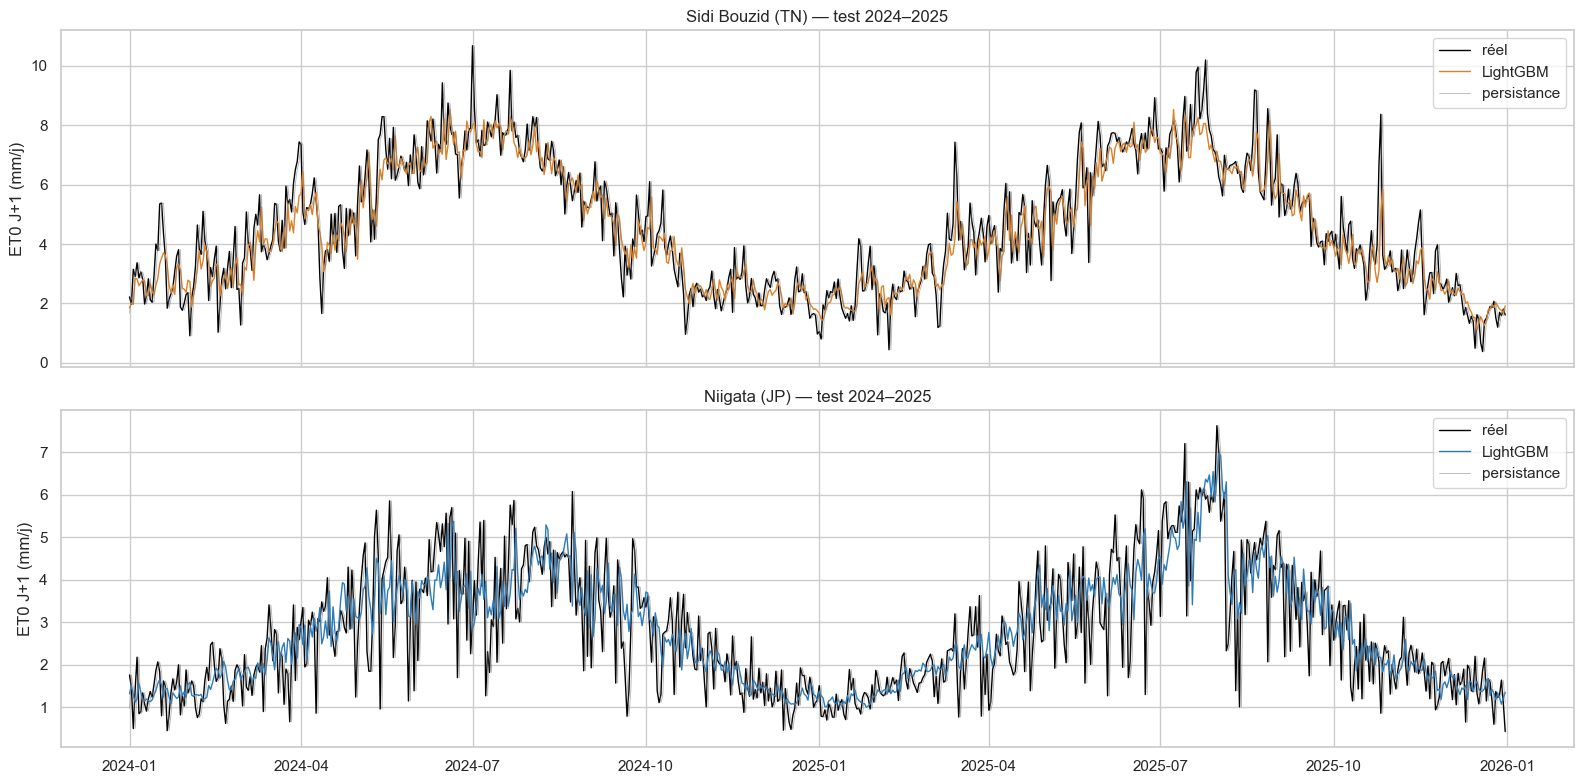

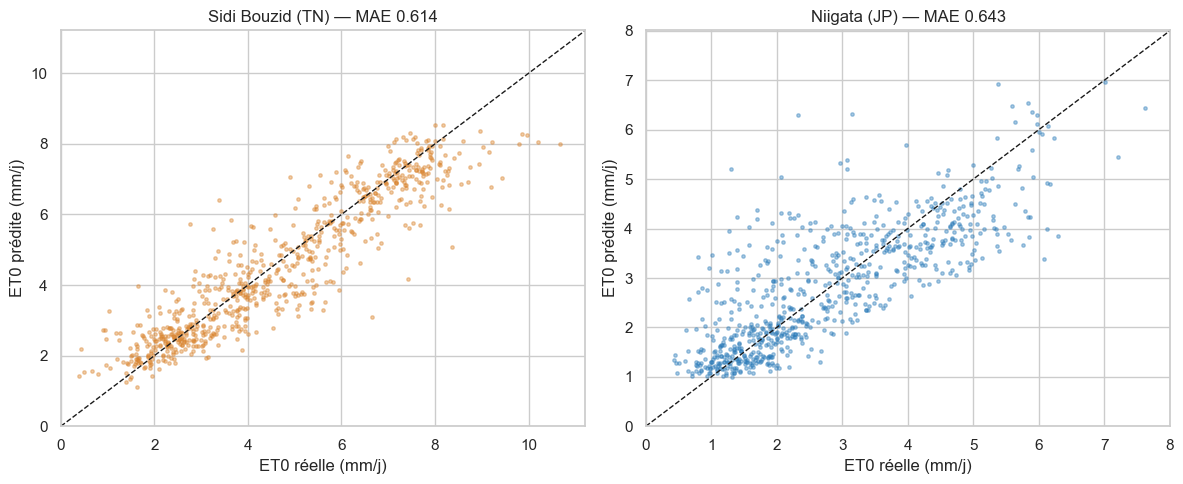

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, site in zip(axes, SITE_CODES):
    g = test[test["site_name"] == site].set_index("target_date").sort_index()
    ax.plot(g.index, g["y"], color="black", lw=1, label="réel")
    ax.plot(g.index, g["lgbm"], color=COLORS[site], lw=1, label="LightGBM")
    ax.plot(g.index, g["persistence"], color="grey", lw=0.6, alpha=0.6, label="persistance")
    ax.set_title(f"{SITE_LABEL[site]} — test 2024–2025")
    ax.set_ylabel("ET0 J+1 (mm/j)")
    ax.legend(loc="upper right")
fig.tight_layout()
mlflow.log_figure(fig, "fig_test_series.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, site in zip(axes, SITE_CODES):
    g = test[test["site_name"] == site]
    ax.scatter(g["y"], g["lgbm"], s=6, alpha=0.4, color=COLORS[site])
    lim = [0, float(max(g["y"].max(), g["lgbm"].max())) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("ET0 réelle (mm/j)")
    ax.set_ylabel("ET0 prédite (mm/j)")
    ax.set_title(f"{SITE_LABEL[site]} — MAE {metrics_by_site[site]['lightgbm']['MAE']:.3f}")
fig.tight_layout()
mlflow.log_figure(fig, "fig_test_scatter.png")
plt.show()

## 9. Importance des variables (gain) et contributions SHAP (natives LightGBM)

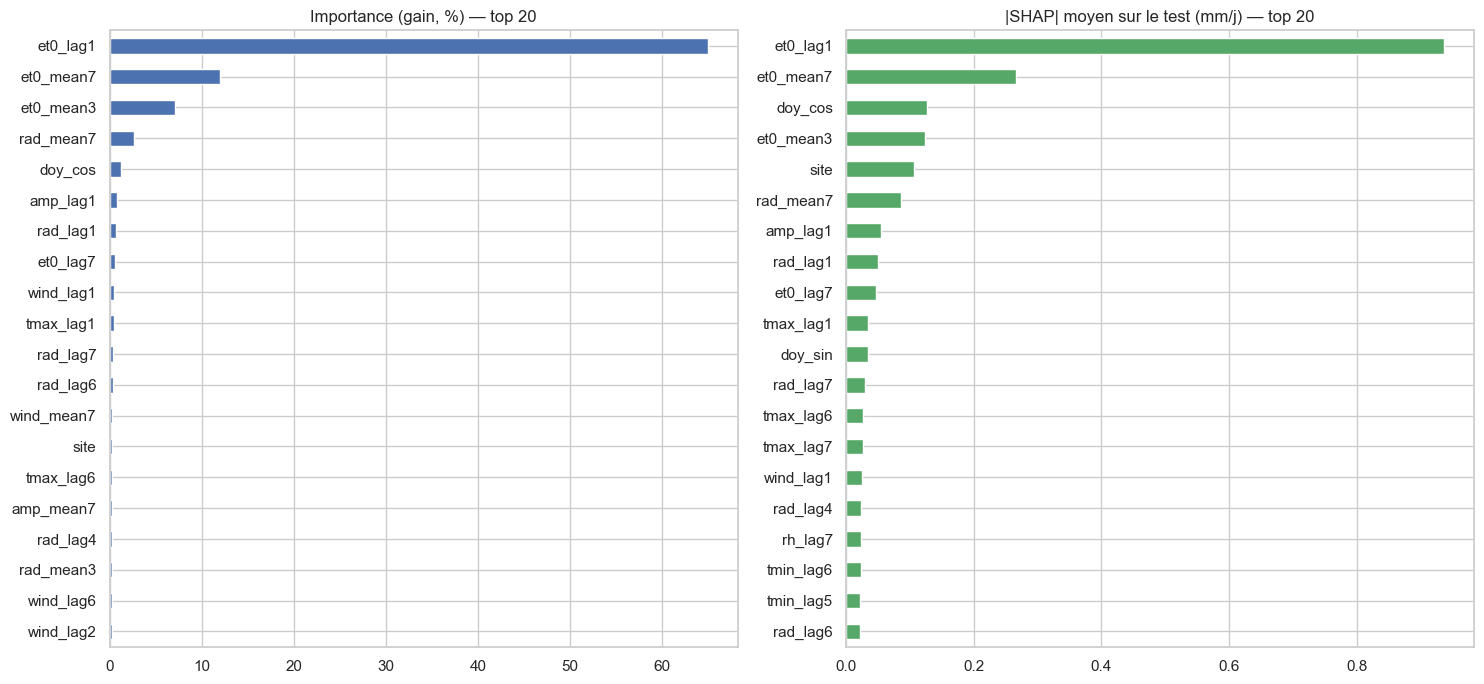

In [29]:
booster = final.booster_
imp = pd.Series(booster.feature_importance(importance_type="gain"), index=FEATURES).sort_values()
contrib = booster.predict(X_te, pred_contrib=True)  # SHAP TreeExplainer natif : n × (variables + biais)
shap_mean = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
(imp / imp.sum() * 100).tail(20).plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Importance (gain, %) — top 20")
shap_mean.tail(20).plot.barh(ax=axes[1], color="#55a868")
axes[1].set_title("|SHAP| moyen sur le test (mm/j) — top 20")
fig.tight_layout()
mlflow.log_figure(fig, "fig_importance.png")
plt.show()

## 10. Export des artefacts et contrôle de rechargement

In [30]:
model_path = ARTIFACTS / "et0_lgbm.txt"
booster.save_model(str(model_path))

features_meta = {
    "features": FEATURES,
    "categorical": ["site"],
    "site_codes": SITE_CODES,
    "target": "ET0 FAO-56 (Open-Meteo) du jour J+1, mm/j",
    "row_definition": "une ligne = jour J (dernier jour connu) pour un site",
    "lag_convention": "{var}_lag{k} = valeur du jour J-(k-1) ; lag1 = jour J ; k = 1..7",
    "rolling": "{var}_mean3 / {var}_mean7 = moyennes glissantes se terminant au jour J",
    "amplitude": "amp_lag1 = Tmax-Tmin du jour J ; amp_mean7 = moyenne sur 7 jours",
    "doy": "doy_sin/doy_cos = sin/cos(2π·jour_de_l_année(J+1)/365.25)",
    "source_columns": SOURCE,
    "history_days_required": 7,
    "lightgbm_version": lgb.__version__,
}
with open(ARTIFACTS / "et0_features.json", "w", encoding="utf-8") as f:
    json.dump(features_meta, f, ensure_ascii=False, indent=2)

metrics = {
    "model": "LightGBM (et0_lgbm.txt)",
    "test_period": "2024-01-01 → 2025-12-31 (date cible)",
    "train_period": "2015 → 2023 (train ≤ 2022 + validation 2023)",
    "test": metrics_by_site,
    "mae_train_val_test": OVERFIT,
    "farm_translation": FARM_TRANSLATION,
    "val_mae_best_trial": round(float(best["val_mae"]), 4),
    "best_params": BEST_PARAMS,
    "n_estimators": N_ESTIMATORS,
    "n_train_rows": int(len(X_trva)),
    "n_test_rows": int(len(X_te)),
    "hargreaves_note": "Hargreaves calculé avec les températures observées de J+1 (≈ prévision parfaite)",
}
with open(ARTIFACTS / "et0_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

# Contrôle : le modèle rechargé depuis le fichier donne exactement les mêmes prédictions
reloaded = lgb.Booster(model_file=str(model_path))
assert reloaded.feature_name() == FEATURES, "ordre des variables différent après rechargement"
assert np.allclose(reloaded.predict(X_te), test["lgbm"].to_numpy(), atol=1e-9)
for name in ("et0_lgbm.txt", "et0_features.json", "et0_metrics.json"):
    mlflow.log_artifact(str(ARTIFACTS / name))
print("Artefacts écrits et rechargés sans écart :", [p.name for p in sorted(ARTIFACTS.glob("et0_*"))])

Artefacts écrits et rechargés sans écart : ['et0_features.json', 'et0_lgbm.txt', 'et0_metrics.json']


## Résumé des métriques

In [31]:
print(f"=== 02_train_et0_lightgbm — exécuté en {time.perf_counter() - T0:.1f} s ===")
print(f"Meilleur essai : MAE validation 2023 = {best['val_mae']:.3f} mm/j ; {N_ESTIMATORS} arbres")
print("\nTest 2024–2025 (ET0 J+1, mm/j)")
print(f"{'site':10s} {'modèle':12s} {'MAE':>7s} {'RMSE':>7s} {'R²':>7s}")
for site in [*SITE_CODES, "global"]:
    for name in ("lightgbm", "persistance", "hargreaves"):
        m = metrics_by_site[site][name]
        print(f"{site:10s} {name:12s} {m['MAE']:7.3f} {m['RMSE']:7.3f} {m['R2']:7.3f}")
    print(f"{'':10s} → gain MAE vs persistance : {metrics_by_site[site]['gain_mae_vs_persistence_pct']:+.1f} %")
print("\nContrôle du surapprentissage (MAE globale, mm/j)")
for row, vals in OVERFIT.items():
    print(f"  {row:50s} {vals['global']:.3f}")
print(f"\nFerme de démo (Sidi Bouzid) : erreur moyenne {FARM_TRANSLATION['mae_lightgbm_m3_day']:.1f} m³/j "
      f"= {FARM_TRANSLATION['mae_lightgbm_pct_quota']:.1f} % du quota de {QUOTA:.0f} m³/j "
      f"(persistance : {FARM_TRANSLATION['mae_persistence_m3_day']:.1f} m³/j)")
mlflow.end_run()

=== 02_train_et0_lightgbm — exécuté en 18.4 s ===
Meilleur essai : MAE validation 2023 = 0.605 mm/j ; 119 arbres

Test 2024–2025 (ET0 J+1, mm/j)
site       modèle           MAE    RMSE      R²
tunisia    lightgbm       0.614   0.830   0.849
tunisia    persistance    0.687   0.919   0.814
tunisia    hargreaves     0.694   0.917   0.815
           → gain MAE vs persistance : +10.7 %
japan      lightgbm       0.643   0.874   0.632
japan      persistance    0.767   1.073   0.446
japan      hargreaves     0.707   0.852   0.650
           → gain MAE vs persistance : +16.1 %
global     lightgbm       0.628   0.852   0.826
global     persistance    0.727   0.999   0.760
global     hargreaves     0.700   0.885   0.812
           → gain MAE vs persistance : +13.6 %

Contrôle du surapprentissage (MAE globale, mm/j)
  1. train ≤ 2022 (sélection, en-échantillon)        0.375
  2. validation 2023 (sélection, hors-échantillon)   0.605
  3. train+val ≤ 2023 (final, en-échantillon)        0.390
  4. te